### 27. Apply an Elastix affine registration result with MONAI

This notebook registers two 3D lung CT images with an affine transform in itk-elastix, converts the resulting transform to the MONAI convention with `monai.data.itk_torch_bridge`, and resamples the moving image with MONAI's `Affine` transform. MONAI reproduces the Elastix result image voxel for voxel.

This is the reverse direction of [example 18](ITK_Example18_MONAI_affine_Elastix_nonlinear.ipynb), which converts a MONAI affine transform into an initial transform for Elastix.

In [1]:
import itk
import matplotlib.pyplot as plt
import numpy as np
import torch

from monai.data import itk_torch_bridge
from monai.transforms import Affine

### Register with Elastix

The fixed and moving images have different sizes and origins, and anisotropic spacing.

Within half a voxel beyond the outermost voxel centers, ITK extends the edge voxel values while MONAI blends them with its zero padding. Setting the one-voxel border of the moving image to zero makes the two resampling results directly comparable.

In [2]:
fixed_image = itk.imread("data/CT_3D_lung_fixed.mha", itk.F)
moving_image = itk.imread("data/CT_3D_lung_moving.mha", itk.F)
ndim = fixed_image.ndim

moving_image[:] = np.pad(moving_image[(slice(1, -1),) * ndim], pad_width=1)

for name, image in [("Fixed", fixed_image), ("Moving", moving_image)]:
    print(
        f"{name} size: {tuple(image.GetLargestPossibleRegion().GetSize())}, "
        f"spacing: {tuple(image.GetSpacing())}, origin: {tuple(image.GetOrigin())}"
    )

Fixed size: (115, 157, 129), spacing: (1.366, 1.366, 2.5), origin: (-153.827, -150.352, -1434.5)
Moving size: (115, 166, 131), spacing: (1.366, 1.366, 2.5), origin: (-161.831, -162.449, -1399.5)


The Elastix result image is resampled with linear interpolation, to match MONAI's bilinear resampling below.

In [3]:
parameter_object = itk.ParameterObject.New()
affine_parameter_map = itk.ParameterObject.GetDefaultParameterMap("affine")
affine_parameter_map["ResampleInterpolator"] = ["FinalLinearInterpolator"]
parameter_object.AddParameterMap(affine_parameter_map)

result_image, result_transform_parameters = itk.elastix_registration_method(
    fixed_image, moving_image, parameter_object=parameter_object, log_to_console=False
)

### Read the affine transform parameters

Elastix stores an affine transform as its matrix, row by row, followed by its translation. The transform maps a point $x$ of the fixed image to the point $A(x - c) + c + t$ of the moving image, where $c$ is the `CenterOfRotationPoint`.

In [4]:
parameter_map = result_transform_parameters.GetParameterMap(0)
assert parameter_map["Transform"] == ("AffineTransform",)

transform_parameters = np.array(parameter_map["TransformParameters"], dtype=float)
matrix = transform_parameters[: ndim * ndim].reshape(ndim, ndim)
translation = transform_parameters[ndim * ndim :].tolist()
center_of_rotation = [float(c) for c in parameter_map["CenterOfRotationPoint"]]

print("Matrix:\n", matrix)
print("Translation:", translation)
print("Center of rotation:", center_of_rotation)

Matrix:
 [[ 1.02598605  0.01140909 -0.00988135]
 [ 0.01245025  1.05292483 -0.00115074]
 [-0.01182175 -0.03164625  1.01392196]]
Translation: [-5.171609354770805, -6.3939953908076745, 38.4258795932374]
Center of rotation: [-75.96499999999999, -43.804, -1274.5]


### Convert the transform to a MONAI affine matrix

ITK transforms act on physical points, while a MONAI affine matrix acts on voxel indices measured from the center of the image grid. `itk_to_monai_affine` accounts for the moving image's spacing, direction and grid center, and for the Elastix center of rotation.

MONAI resamples the moving image onto a grid of the size we request, centered on the moving image grid. To land on the fixed image grid instead, we precede the transform with a mapping from the fixed image grid to the moving image grid: the change of voxel size and direction, plus the offset between the two grid centers. `itk_to_monai_affine` computes this mapping when given `reference_image=fixed_image`, but as of MONAI 1.6 it assumes that both images have the same size, which is not the case here. So we compose the mapping ourselves.

In [5]:
def index_to_physical_matrix(image):
    direction = itk.array_from_matrix(image.GetDirection())
    return direction @ np.diag(image.GetSpacing())


fixed_to_moving_grid = itk_torch_bridge.itk_to_monai_affine(
    moving_image,
    matrix=index_to_physical_matrix(fixed_image)
    @ np.linalg.inv(index_to_physical_matrix(moving_image)),
    translation=np.subtract(
        itk_torch_bridge.get_itk_image_center(fixed_image),
        itk_torch_bridge.get_itk_image_center(moving_image),
    ).tolist(),
)

monai_affine = (
    itk_torch_bridge.itk_to_monai_affine(
        moving_image,
        matrix=matrix,
        translation=translation,
        center_of_rotation=center_of_rotation,
    )
    @ fixed_to_moving_grid
)
print(monai_affine)

tensor([[ 1.0260,  0.0114, -0.0181,  2.0735],
        [ 0.0125,  1.0529, -0.0021, -0.3250],
        [-0.0065, -0.0173,  1.0139,  0.3704],
        [ 0.0000,  0.0000,  0.0000,  1.0000]], dtype=torch.float64)


### Resample the moving image with MONAI

`itk_image_to_metatensor` converts the moving image to a channel-first MONAI `MetaTensor` whose spatial axes follow ITK's $(x, y, z)$ order. MONAI's `Affine` transform then resamples it onto a grid with the fixed image's size.

In [6]:
moving_metatensor = itk_torch_bridge.itk_image_to_metatensor(moving_image)
fixed_size = list(fixed_image.GetLargestPossibleRegion().GetSize())

monai_transform = Affine(
    affine=monai_affine,
    mode="bilinear",
    padding_mode="zeros",
    dtype=torch.float64,
    image_only=True,
)
output_metatensor = monai_transform(moving_metatensor, spatial_size=fixed_size)

`metatensor_to_itk_image` converts the output back to an ITK image. Its spatial metadata comes from the output `MetaTensor`'s affine, which records where each voxel was sampled in the moving image. The voxels lie on the fixed image grid, so the result takes its spacing, origin and direction from the fixed image instead.

In [7]:
monai_result_image = itk_torch_bridge.metatensor_to_itk_image(output_metatensor)
monai_result_image.CopyInformation(fixed_image)

### Compare the Elastix and MONAI results

In [8]:
elastix_result = np.asarray(result_image)
monai_result = np.asarray(monai_result_image)
difference = elastix_result - monai_result
print(f"Maximum absolute difference: {np.abs(difference).max():.2g}")

np.testing.assert_allclose(monai_result, elastix_result, atol=1e-3)

Maximum absolute difference: 6.1e-05


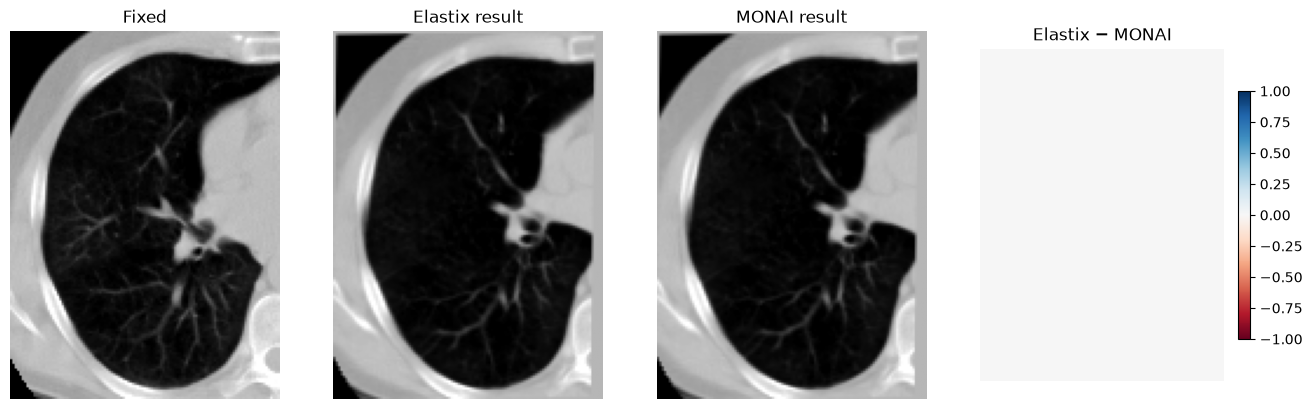

In [9]:
# Show the central axial slice
z = fixed_image.shape[0] // 2
ct_window = {"cmap": "gray", "vmin": -1000, "vmax": 400}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, image, title in zip(
    axes[:3],
    [fixed_image, result_image, monai_result_image],
    ["Fixed", "Elastix result", "MONAI result"],
):
    ax.imshow(np.asarray(image)[z], **ct_window)
    ax.set_title(title)

shown = axes[3].imshow(difference[z], cmap="RdBu", vmin=-1, vmax=1)
axes[3].set_title("Elastix − MONAI")
fig.colorbar(shown, ax=axes[3], fraction=0.046)

for ax in axes:
    ax.axis("off")
plt.show()